In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

def lorenz_rhs(t, state, sigma=10.0, rho=28.0, beta=8.0/3.0):
    """Right-hand side of the Lorenz system."""
    x, y, z = state
    # TODO: write the three derivatives here, following the equations above
    dx = sigma * (y - x)
    dy = x * (rho - z) - y
    dz = x * y - beta * z
    return [dx, dy, dz]

# Integrate a trajectory
# Lorenz is usually integrated with a fixed small timestep for ML work,
# because the reservoir needs evenly-spaced samples.
dt = 0.02
t_max = 250.0
t_eval = np.arange(0, t_max, dt)

initial_state = [1.0, 1.0, 1.0]  # arbitrary starting point

sol = solve_ivp(
    lorenz_rhs, (0, t_max), initial_state,
    t_eval=t_eval, method='RK45', rtol=1e-9, atol=1e-9
)

# sol.y is shape (3, num_timesteps) — the trajectory
data = sol.y.T  # transpose to (num_timesteps, 3) — each row is a state
print(f"Generated {data.shape[0]} timesteps of Lorenz data, each {data.shape[1]}-dimensional")

Generated 12500 timesteps of Lorenz data, each 3-dimensional


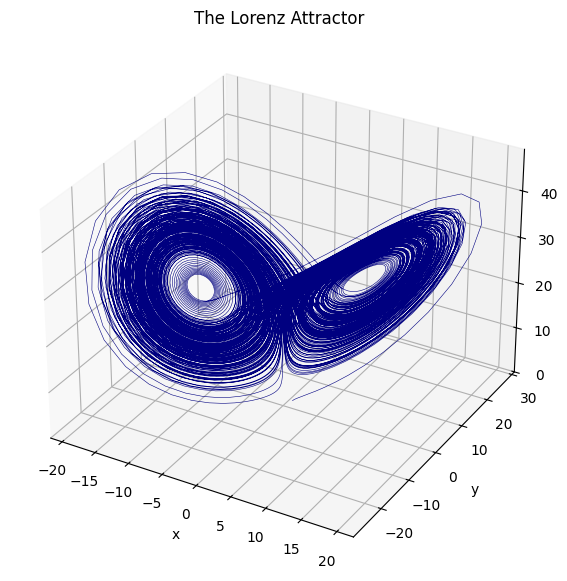

In [3]:
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')
ax.plot(data[:, 0], data[:, 1], data[:, 2], linewidth=0.4, color='navy')
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_zlabel('z')
ax.set_title('The Lorenz Attractor')
plt.show()